# Exploratory Data Analysis

## Project Objective

This analysis examines inventory production and waste in a bakery and grocery retail dataset of 19,321 records from three stores (ST01 to ST03), covering all four seasons from 2023-01-01 till 2024-12-31. The objective is to measure how much recorded production goes unsold and to identify where that unsold inventory is concentrated. 

It examines waste across products, categories, perishability levels, stores and seasons, to establish which product characteristics and operating conditions are associated with higher waste.

The dataset has 40 columns covering customers, transactions, pricing and inventory. The analysis uses the inventory fields (Units_Produced, Units_Sold, Unsold_Units, Waste_Pct, Shelf_Life_Days) together with product, category, perishability, storage, store, season and day of week. Customer, pricing and payment fields are out of scope.

Two waste measures are used. The pooled waste rate (total unsold ÷ total produced) weights each record by volume and is used for headline figures. Average Waste_Pct is the mean of record-level percentages, so every record counts equally and small batches have a large influence. It therefore runs higher, and each result states which measure it uses.

## Business Questions

1. How much inventory goes unsold?
2. Which products generate the most waste?
3. Does perishability influence waste?
4. Are stores producing more than they sell?
5. Which stores manage inventory most efficiently?
6. Does seasonality influence product waste?
7. Does production efficiency vary by category?

## Reading the Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
bakery_sales = pd.read_csv("/home/andi/Documents/Bakery/bakery_sales.csv")

In [4]:
bakery_sales.head().T

,0,1,2,3,4
Order_ID,ORD00001,ORD00001,ORD00002,ORD00002,ORD00002
Customer_ID,CUST0328,CUST0328,CUST0016,CUST0016,CUST0016
Customer_Age,46,46,21,21,21
Customer_Gender,Other,Other,Female,Female,Female
Customer_Segment,Young Professional,Young Professional,Student,Student,Student
Loyalty_Member,Yes,Yes,No,No,No
Date,2023-01-01,2023-01-01,2023-01-01,2023-01-01,2023-01-01
Year,2023,2023,2023,2023,2023
Month,1,1,1,1,1
Day,1,1,1,1,1


In [25]:
bakery_sales['Date'].agg(['min','max'])

min   2023-01-01
max   2024-12-31
Name: Date, dtype: datetime64[us]

## Analysing the Data

In [5]:
bakery_sales.shape

(19321, 40)

In [6]:
bakery_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  str    
 1   Customer_ID          19321 non-null  str    
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  str    
 4   Customer_Segment     19321 non-null  str    
 5   Loyalty_Member       19321 non-null  str    
 6   Date                 19321 non-null  str    
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  str    
 11  Weekend              19321 non-null  str    
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  str    
 14  Season               19321 non-null  str    
 15  Festival             3315 non-null   str    
 1

In [7]:
bakery_sales.duplicated(subset=['Order_ID', 'Product']).sum()

np.int64(0)

In [8]:
bakery_sales['Date'] = pd.to_datetime(bakery_sales['Date'])

In [9]:
null_pct = (bakery_sales.isnull().mean() * 100)
null_pct = null_pct[null_pct > 0].round(2)

null_pct

Festival          82.84
Promotion_Type    71.56
dtype: float64

In [10]:
bakery_sales.duplicated().sum()

np.int64(0)

In [11]:
numerical_cols = ['Units_Produced','Units_Sold', 'Unsold_Units','Waste_Pct','Shelf_Life_Days']

categorical_cols = ['Product','Category','Perishability','Storage_Type','Store_ID','Season','Day_of_Week']

In [12]:
bakery_sales[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Units_Produced,19321.0,4.221469,3.635227,2.0,2.0,3.0,5.0,49.0
Units_Sold,19321.0,3.046788,3.038092,1.0,1.0,2.0,4.0,37.0
Unsold_Units,19321.0,1.174680,0.783283,1.0,1.0,1.0,1.0,16.0
Waste_Pct,19321.0,34.118715,12.734206,4.2,25.0,33.3,50.0,50.0
Shelf_Life_Days,19321.0,61.117333,103.611553,1.0,3.0,5.0,82.0,729.0


In [13]:
bakery_sales[bakery_sales['Units_Produced'] !=
    bakery_sales['Units_Sold'] + bakery_sales['Unsold_Units']].shape

(0, 40)

### Data Inspection Summary

* The dataset contains 19,321 records and 40 columns, with one row per order and product. There are no fully duplicated records and no duplicates on Order_ID and Product.
* Missing values appear only in Festival (82.8%) and Promotion_Type (71.6%). Promotion_Applied is complete, so these nulls most likely mean "no festival" or "no promotion" rather than lost data. They are left as is.
* `Units_Produced` = `Units_Sold` + `Unsold_Units` for every record, so the inventory fields are internally consistent and Unsold_Units is not an independent measure.
* Every record has at least one unit sold and one unsold. The dataset therefore only describes production runs with leftover stock.
* Later analysis is limited to the columns that answer the business questions.

## Univariate Analysis

### Numerical Univariate Analysis

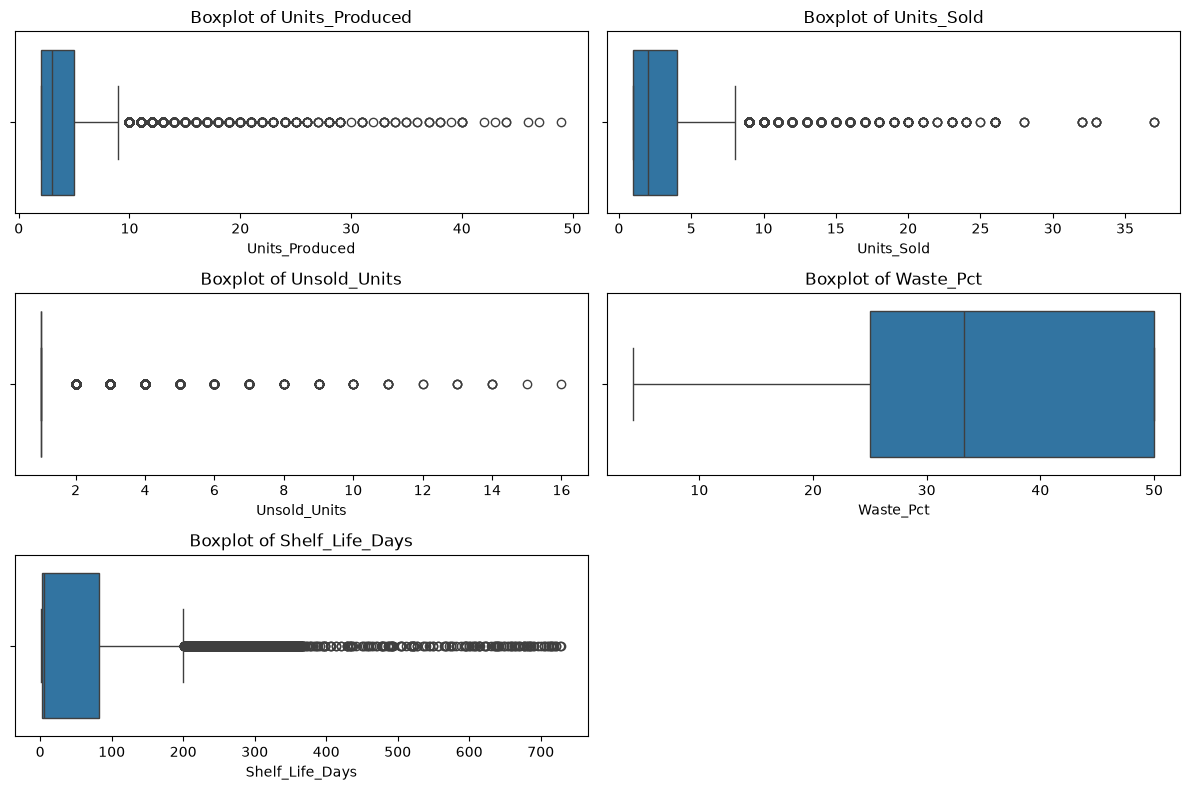

In [14]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(data=bakery_sales, x=col, ax=axes[i])
    axes[i].set_title(f'Boxplot of {col}')

# Remove unused subplot
for j in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### Summary
* `Units_Produced` is strongly right-skewed with a long tail. The box runs from about 2 to 5 with a median near 3, and the upper whisker stops at about 9.

* `Units_Sold` has the same shape on a smaller scale. The box runs from about 1 to 4, the median is about 2, and the whisker ends near 8. Outliers stretch out to about 37.

* `Unsold_Units` has almost no spread. The box has collapsed to a line at 1, meaning at least three quarters of the values are 1, and everything from 2 to 16 is shown as an outlier. The minimum of 1 also suggests there are no zero-unsold records, which may be worth checking.

* `Waste_Pct` is the odd one out. It has no outliers, a box from about 25 to 50, a median of about 33, and a lower whisker down to about 4. The upper edge is a hard cap at 50, so at least a quarter of records sit exactly at 50. That looks structural rather than natural, for example small batches (2 produced, 1 sold) or a cap or filter applied upstream.

* `Shelf_Life_Days` is the most extreme. The median is very low (around 5 days), the box runs from about 3 to 83, the whisker ends near 200, and there is a dense wall of outliers out to about 730. That pattern usually points to two or more product types mixed together, such as fresh items alongside long-life ones, rather than bad data.

### Categotical Univariate Analysis

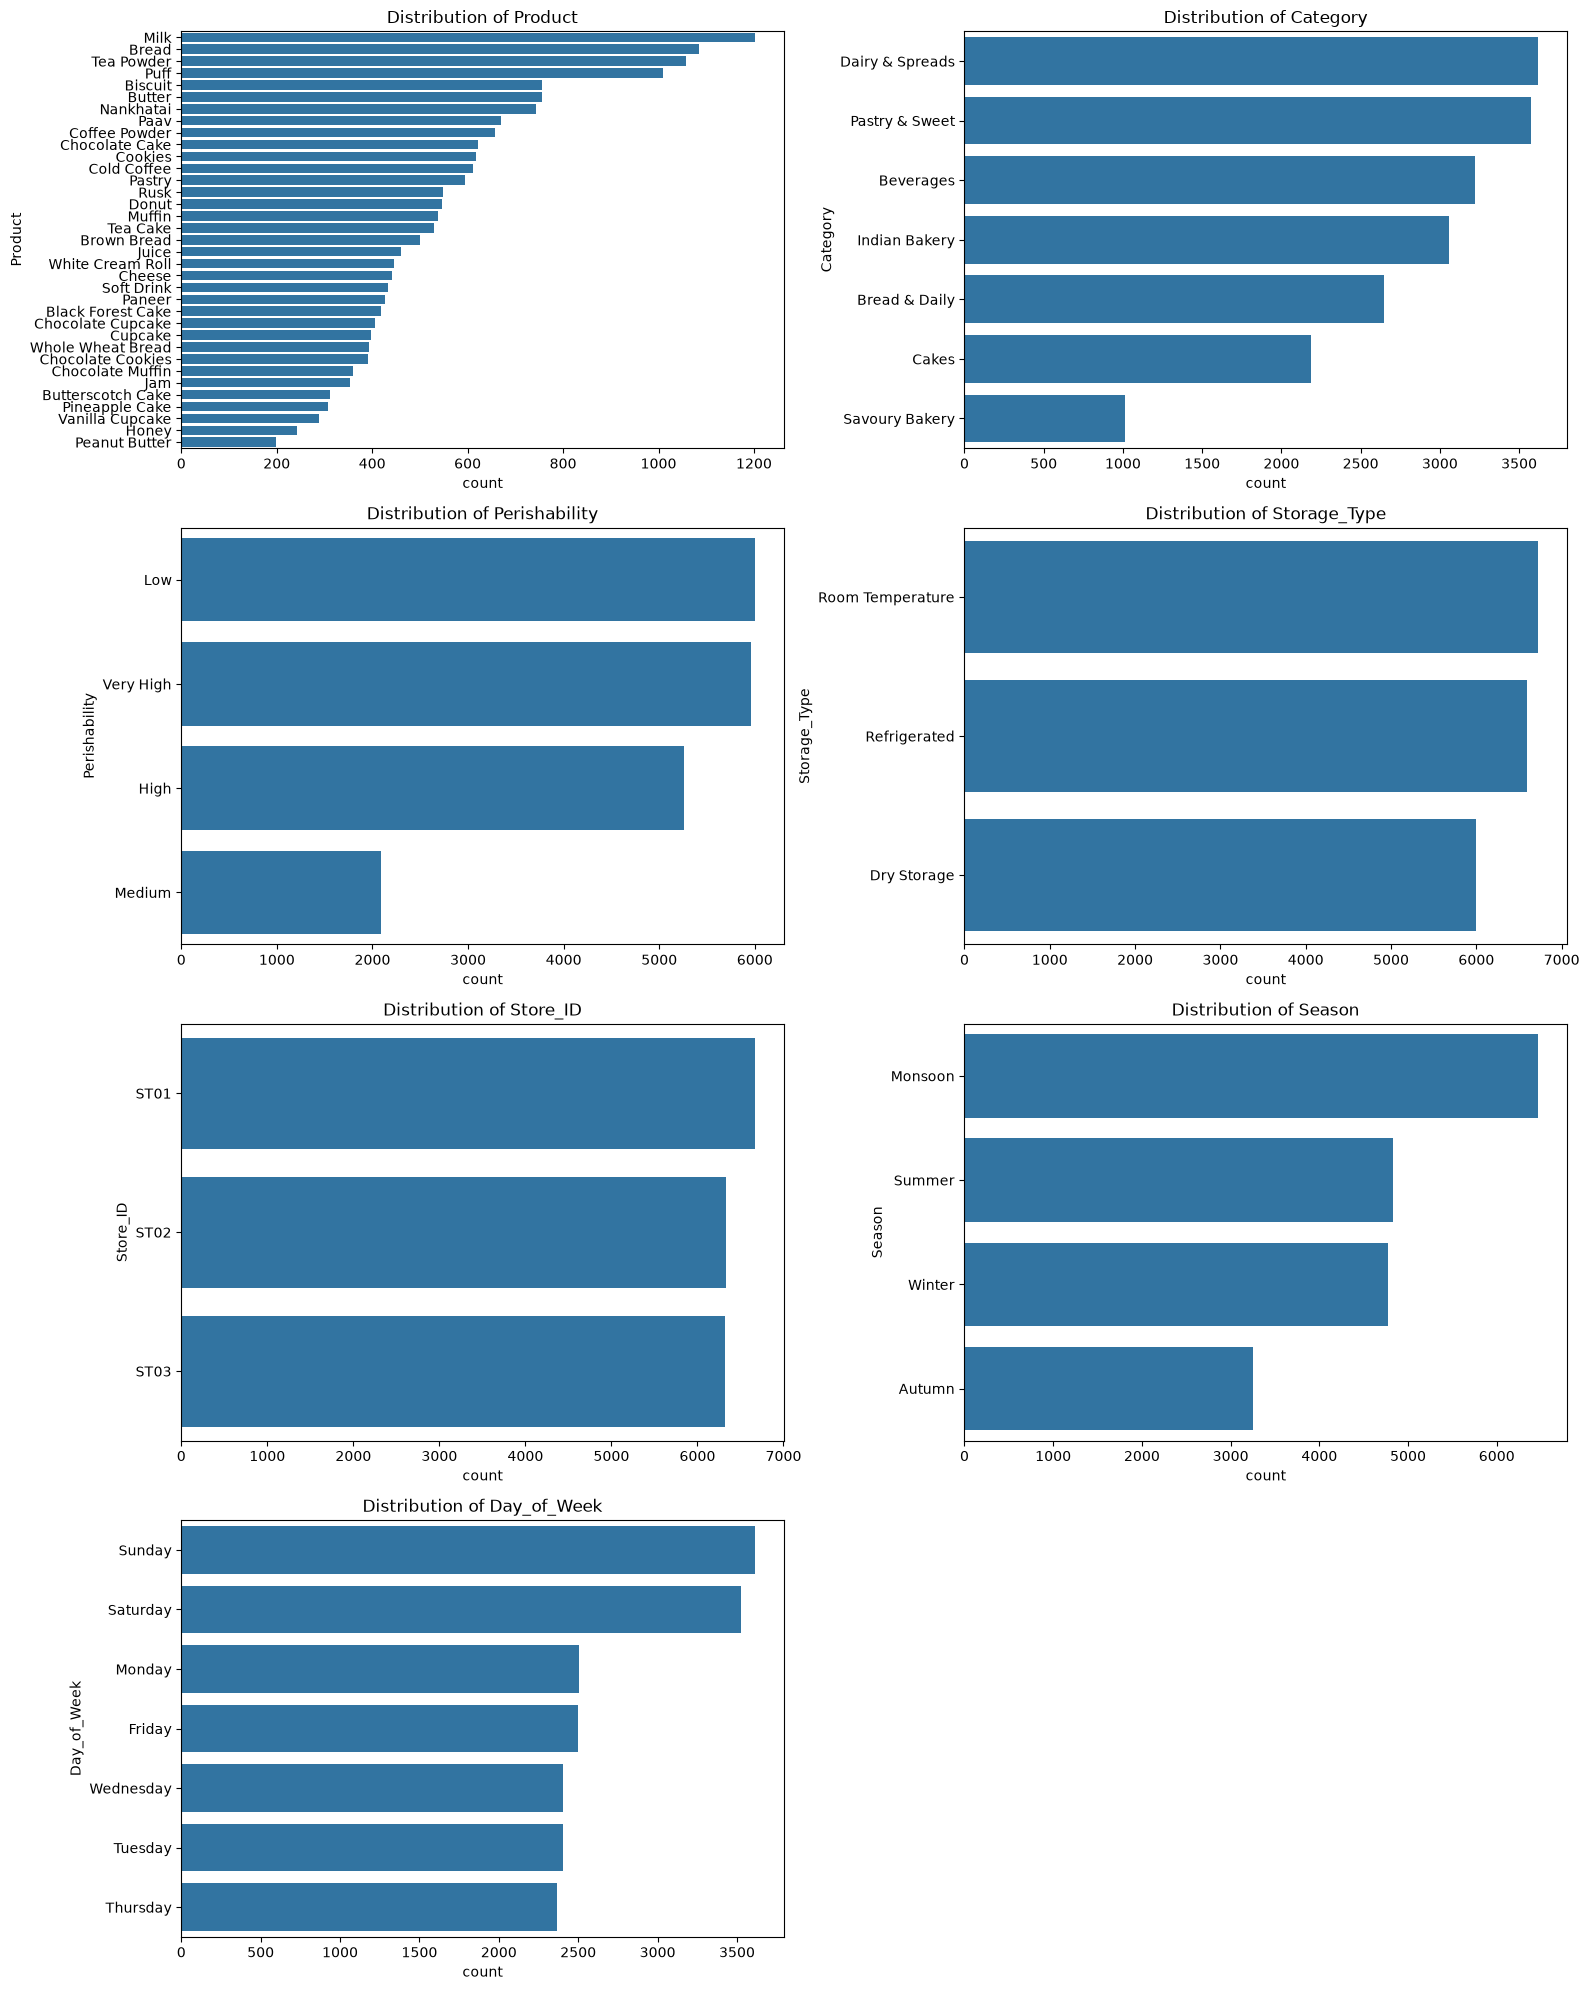

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(
        data=bakery_sales,
        y=col,
        order=bakery_sales[col].value_counts().index,
        ax=axes[i]
    )
    axes[i].set_title(f'Distribution of {col}')

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### Summary
* There are `35 distinct products`. `Milk` is the most frequent (about 1,200 records), followed by `Bread, Tea Powder and Puff`, each at roughly 1,000 or more. There is a clear drop to around 750 for `Biscuit, Butter and Nankhatai`, and most remaining products fall between about 200 and 620 records. `Honey and Peanut Butter` are the least frequent.

* `Dairy & Spreads` (about 3,600) and `Pastry & Sweet` (about 3,580) are the largest categories, followed by `Beverages` (about 3,220) and `Indian Bakery` (about 3,050). `Bread & Daily and Cakes` sit lower at about 2,650 and 2,190. `Savoury Bakery` is the smallest at about 1,010, less than a third of the largest category.

* `Low` (about 6,000) and `Very High` perishability (about 5,960) are almost equally common, followed by `High` (about 5,260). `Medium` is the smallest at about 2,090. Roughly 58% of records are `High or Very High perishability`, and the distribution is weighted towards the extremes.

* `Storage_Type` records are fairly evenly spread across `Room Temperature` (about 6,720), `Refrigerated` (about 6,590) and `Dry Storage` (about 6,000).

* The three stores are well balanced. `ST01` has slightly more records (about 6,670) than `ST02` and `ST03` (about 6,330 and 6,320).

* `Monsoon` season accounts for about a third of records (about 6,460), while `Summer and Winter` are similar at about 4,830 and 4,770. `Autumn` is the smallest at about 3,260, or roughly 17%. This imbalance may reflect how many trading days were captured per season rather than seasonal demand.

* Sunday (about 3,610) and Saturday (about 3,530) are the busiest days. Weekdays are fairly even, between about 2,370 and 2,500. The two weekend days account for roughly 37% of records, against 29% if records were spread evenly.

### Univariate Analysis Summary

* The numeric variables are heavily right-skewed, and the flagged outliers form continuous tails rather than isolated anomalies, so they are retained as genuine observations.
* The categorical variables show broad coverage across stores, storage types and categories, with concentration in a handful of staple products and in weekend and monsoon records. All categorical figures are counts of records, not units or revenue, so they describe how often something appears in the data rather than how much it sells.

## Bivariate Analysis

### Production and Inventory Utilisation
Business question: How much inventory goes unsold?

In [16]:
bakery_sales[['Units_Produced', 'Units_Sold', 'Unsold_Units']].sum()

Units_Produced    81563
Units_Sold        58867
Unsold_Units      22696
dtype: int64

The dataset records 81,563 units produced, of which 58,867 were sold and 22,696 remained unsold. This indicates that approximately 27.8% of recorded production remained unsold. 

### Product-Level Waste
Business question: Which products generate the most waste?

In [17]:
product_waste = bakery_sales.groupby('Product').agg(
    total_produced=('Units_Produced', 'sum'),
    total_sold=('Units_Sold', 'sum'),
    total_unsold=('Unsold_Units', 'sum'))

product_waste['waste_pct'] = (
    product_waste['total_unsold'] /product_waste['total_produced'] * 100).round(2)

product_waste.sort_values('waste_pct', ascending=False).head(10)

,total_produced,total_sold,total_unsold,waste_pct
Product,,,,
Peanut Butter,438,238,200,45.66
Jam,822,463,359,43.67
Butterscotch Cake,716,404,312,43.58
Honey,574,326,248,43.21
Pineapple Cake,714,407,307,43.00
Black Forest Cake,1009,590,419,41.53
Chocolate Cake,1590,967,623,39.18
Chocolate Muffin,965,604,361,37.41
Paneer,1143,717,426,37.27


* Five products exceed 43% waste: Peanut Butter (45.66%), Jam (43.67%), Butterscotch Cake (43.58%), Honey (43.21%) and Pineapple Cake (43.00%). The top ten is made up of three spreads, four cakes (Butterscotch, Pineapple, Black Forest and Chocolate) and Chocolate Muffin, Paneer and Brown Bread.

* Rate and volume tell different stories. The top five produce only 4.0% of units but account for 6.3% of unsold units, and Chocolate Cake has the largest absolute unsold quantity of the ten (623). Honey and Peanut Butter are also the two least frequent products. The heatmap shows Paav, Puff, Cookies and Nankhatai with the lowest waste (roughly 16% to 26%), though Bread and Milk do not fit a simple volume pattern.

### Perishability and Waste
Business question: Does perishability influence waste?

In [18]:
bakery_sales.groupby('Perishability').agg(
    avg_waste_pct=('Waste_Pct', 'mean'),
    total_unsold=('Unsold_Units', 'sum'),
    avg_shelf_life=('Shelf_Life_Days', 'mean')).round(2)

,avg_waste_pct,total_unsold,avg_shelf_life
Perishability,,,
High,34.95,5348,4.13
Low,33.45,8595,175.09
Medium,37.13,2158,46.00
Very High,32.99,6595,2.03


* Perishability shows no clear relationship with waste.
* Average `Waste_Pct` is 37.13% for `Medium, 34.95% for High, 33.45% for Low and 32.99% for Very High.
* The spread is only 4.1 points and does not rise with perishability, so the most perishable items are not the most wasteful.
* Low perishability accounts for the most unsold units (8,595, 37.9%), largely because of its volume. Medium has the highest rate but is the smallest group.

### Store Inventory Efficiency
Business question: Which stores manage inventory most efficiently?

In [19]:
bakery_sales.groupby('Store_ID').agg(
    total_produced=('Units_Produced', 'sum'),
    total_sold=('Units_Sold', 'sum'),
    total_unsold=('Unsold_Units', 'sum'),
    avg_waste_pct=('Waste_Pct', 'mean')).round(2)

,total_produced,total_sold,total_unsold,avg_waste_pct
Store_ID,,,,
ST01,28744,20852,7892,33.74
ST02,26012,18662,7350,34.38
ST03,26807,19353,7454,34.25


* Pooled waste is 27.46% at ST01, 27.81% at ST03 and 28.26% at ST02, a spread of 0.8 points. ST01 produces the most (28,744 units, 35.2%) and has the lowest waste on both measures, while ST02 has the highest. The differences are small, so no store is clearly more efficient.

### Category Production Efficiency
Business question: Does production efficiency vary by category?

In [20]:
category_waste = bakery_sales.groupby('Category').agg(
    total_produced=('Units_Produced', 'sum'),
    total_sold=('Units_Sold', 'sum'),
    total_unsold=('Unsold_Units', 'sum'))

category_waste['waste_pct'] = (
    category_waste['total_unsold'] /
    category_waste['total_produced'] * 100).round(2)

category_waste

,total_produced,total_sold,total_unsold,waste_pct
Category,,,,
Beverages,10252,6872,3380,32.97
Bread & Daily,12979,9933,3046,23.47
Cakes,5609,3414,2195,39.13
Dairy & Spreads,11844,8129,3715,31.37
Indian Bakery,21465,15980,5485,25.55
Pastry & Sweet,12515,8869,3646,29.13
Savoury Bakery,6899,5670,1229,17.81


* Category is the strongest differentiator.
* Pooled waste runs from 39.13% for Cakes through Beverages (32.97%), Dairy & Spreads (31.37%), Pastry & Sweet (29.13%), Indian Bakery (25.55%) and Bread & Daily (23.47%) down to 17.81% for Savoury Bakery, a gap of 21.3 points.
* Indian Bakery is the largest producer (26.3% of units) and has the most unsold units (5,485, 24.2%) despite a below-average rate. Cakes are 6.9% of production but 9.7% of unsold units.

### Seasonal Waste Patterns
Business question: Does seasonality influence product waste?

In [21]:
bakery_sales.groupby('Season').agg(
    total_produced=('Units_Produced', 'sum'),
    total_unsold=('Unsold_Units', 'sum'),
    avg_waste_pct=('Waste_Pct', 'mean')).round(2)

,total_produced,total_unsold,avg_waste_pct
Season,,,
Autumn,13896,3868,34.00
Monsoon,27758,7542,33.61
Summer,19300,5529,34.77
Winter,20609,5757,34.22


* Seasonal differences are small.
* Pooled waste is 28.65% in Summer, 27.93% in Winter, 27.84% in Autumn and 27.17% in Monsoon, a 1.5-point range, and the ordering is the same for average Waste_Pct.
* Monsoon has the highest production (34.0% of units) and the lowest waste rate.

### Bivariate Analysis Summary

* Category is the strongest differentiator (17.8% to 39.1%), followed by individual product.
* Perishability, store and season each move waste by only about 1 to 4 points.
*  Unsold inventory is therefore tied mainly to what is produced rather than where or when.

## Multivariate Analysis

### Shelf Life, Perishability and Waste

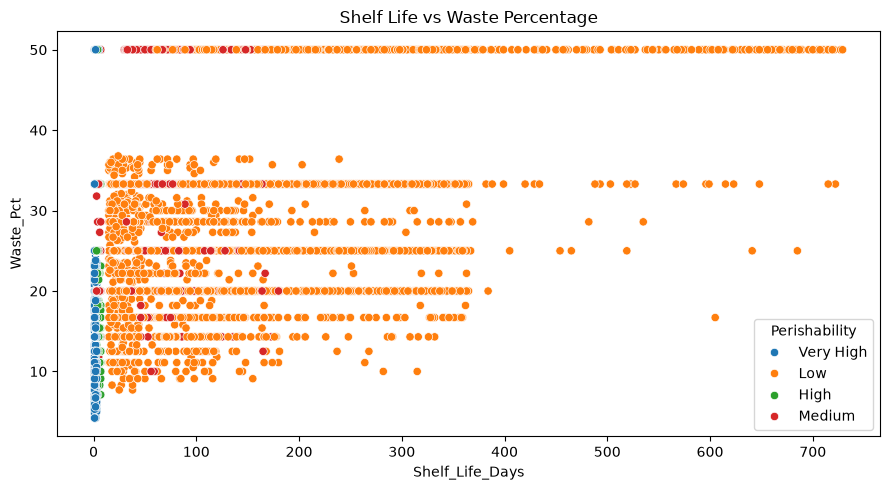

In [22]:
plt.figure(figsize=(9, 5))

sns.scatterplot(data=bakery_sales, x='Shelf_Life_Days', y='Waste_Pct',hue='Perishability')

plt.title('Shelf Life vs Waste Percentage')
plt.tight_layout()
plt.show()

* Very High and High perishability records sit within roughly 10 days of shelf life, while Low spans about 7 to 730 days.
* Waste forms horizontal bands at fixed values (50, 33.3, 28.6, 25, 20, 16.7 and so on), confirming that Waste_Pct depends on small batch ratios.
* There is no visible trend between shelf life and waste. Records with 400 to 730 days of shelf life still show waste of roughly 17% to 50%, so longer shelf life does not protect against waste.

### Store and Category Waste

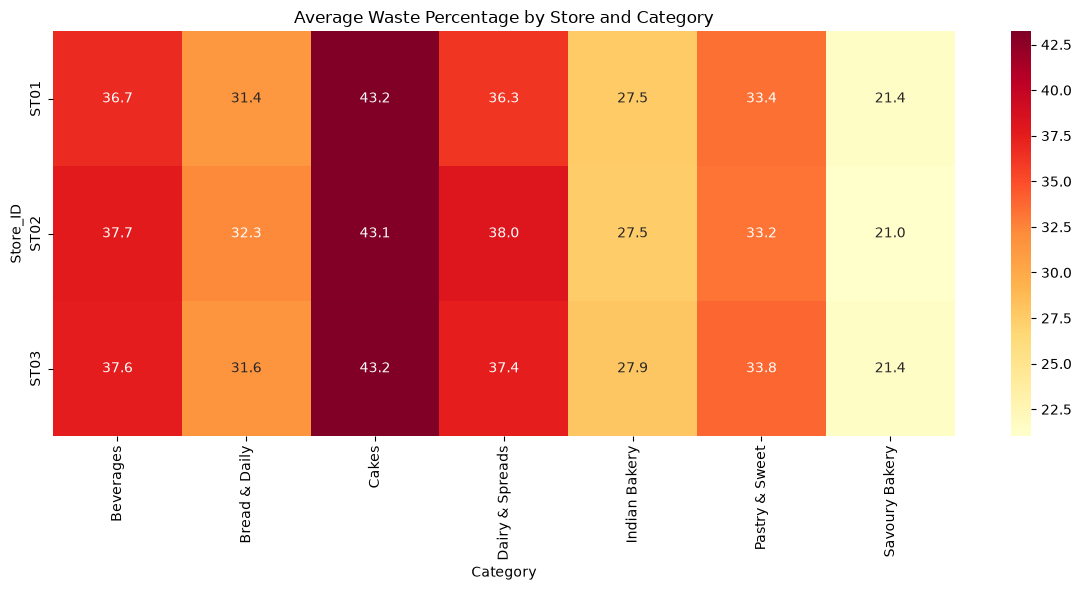

In [23]:
store_category = bakery_sales.pivot_table(
    index='Store_ID',
    columns='Category',
    values='Waste_Pct',
    aggfunc='mean'
)

plt.figure(figsize=(12, 6))

sns.heatmap(store_category, annot=True, fmt='.1f', cmap='YlOrRd')

plt.title('Average Waste Percentage by Store and Category')
plt.tight_layout()
plt.show()

* The pattern is driven by category and is almost identical across stores.
* Cakes are about 43% at all three (43.1 to 43.2), Savoury Bakery about 21% and Indian Bakery about 27.5 to 27.9%.
* The widest store gap in any category is 1.7 points (Dairy & Spreads, 36.3 at ST01 against 38.0 at ST02), so store matters little once category is considered.

### Product and Seasonal Waste

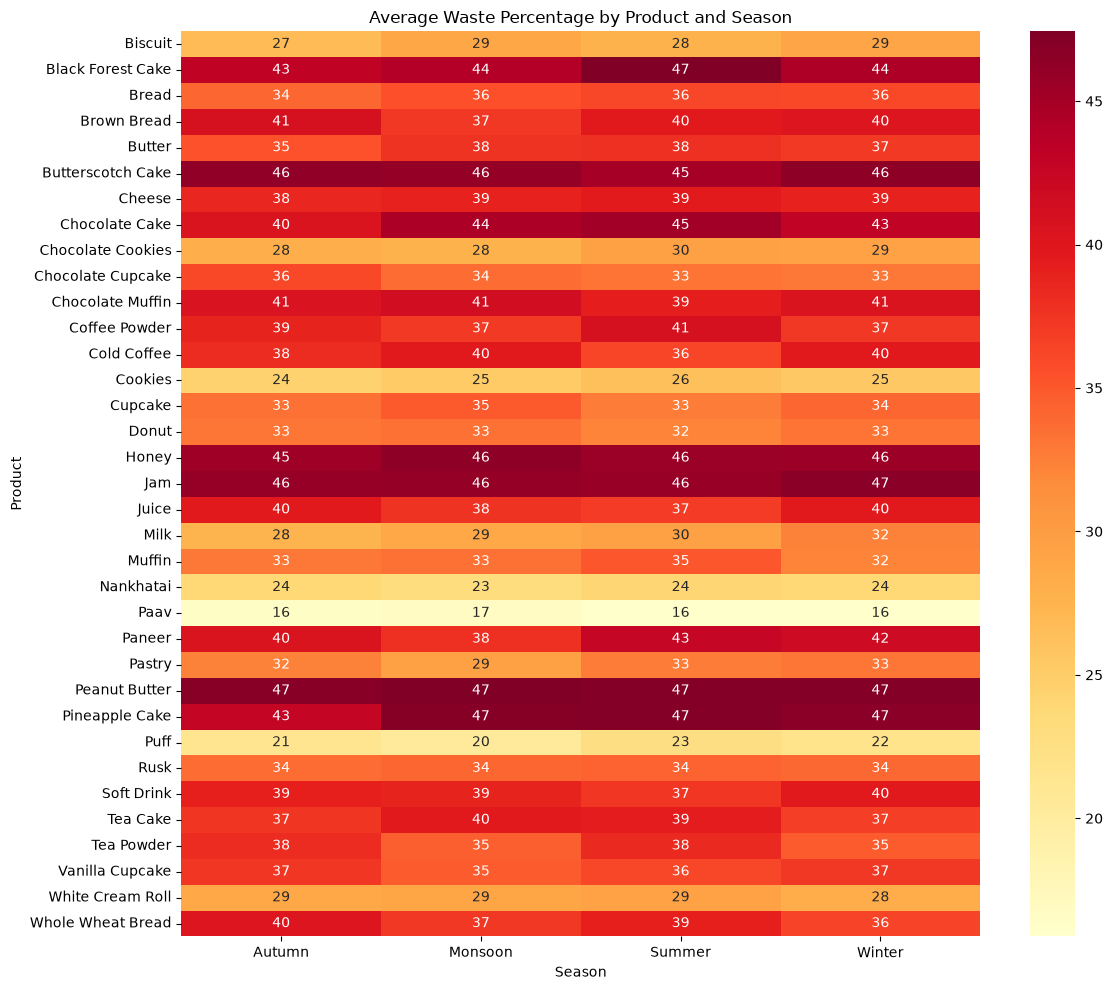

In [24]:
seasonal_waste = bakery_sales.pivot_table(
    index='Product',
    columns='Season',
    values='Waste_Pct',
    aggfunc='mean')

plt.figure(figsize=(12, 10))

sns.heatmap(seasonal_waste, cmap='YlOrRd', annot=True)

plt.title('Average Waste Percentage by Product and Season')
plt.tight_layout()
plt.show()

* Rows differ far more than columns, so product identity matters much more than season. The gap between the lowest- and highest-waste products is 31 points (Paav at 16% against Peanut Butter at 47%), whereas no product moves by more than 5 points across seasons and 17 of the 35 move by 2 points or less. High-waste products stay high in every season (Peanut Butter 47 in all four, Jam 46 to 47, Honey 45 to 46, Butterscotch Cake 45 to 46), and low-waste products stay low (Paav 16 to 17, Puff 20 to 23, Nankhatai 23 to 24, Cookies 24 to 26).
  
* The largest seasonal swings are Chocolate Cake (40 in Autumn to 45 in Summer) and Paneer (38 in Monsoon to 43 in Summer). Black Forest Cake (43 to 47, peaking in Summer) and Pineapple Cake (43 in Autumn against 47 in the other three seasons) move by 4 points, as do Coffee Powder, Cold Coffee, Milk, Pastry, Brown Bread and Whole Wheat Bread. Summer is the outright highest season for eight products, which fits it having the highest overall waste rate, but the effect is small.


* These values are averages of record-level Waste_Pct, rounded to whole numbers, so they run higher than the pooled product rates in the bivariate section (Peanut Butter is 47 here against 45.66 pooled).

### Multivariate Analysis Summary

* Product and category drive waste, while shelf life, store and season add little once they are accounted for.
* High-waste products are consistently high across stores and seasons, with seasonal swings of at most 5 points at product level, which points to production planning at product level rather than seasonal adjustment.

## Key Findings

**Overall Inventory Performance**

* 27.8% of recorded production went unsold (22,696 of 81,563 units).
* The typical record leaves one unit unsold, and about 85% of unsold units are that single unit per record. Waste is therefore widespread rather than driven by a few large overproduction events.

**Product and Category Performance**

* Category is the strongest driver of waste, from Cakes (39.1%) to Savoury Bakery (17.8%).
Spreads and cakes dominate the highest-waste products, led by Peanut Butter (45.7%) and Jam (43.7%).
* Indian Bakery generates the most unsold units in absolute terms (5,485).

**Perishability and Shelf Life**

* Perishability and shelf life show no strong relationship with waste. Average waste ranges only from 33.0% to 37.1%, and Very High perishability has the lowest.
* Low perishability items account for the largest share of unsold units (37.9%) because of volume.

**Store-Level Performance**

* Stores perform similarly, with pooled waste from 27.5% (ST01) to 28.3% (ST02).
* Category-level waste is consistent across all three stores.

**Seasonal and Temporal Patterns**

* Seasonal differences are small (27.2% in Monsoon to 28.7% in Summer). Product rankings are stable across seasons, and no product's average waste moves by more than 5 points between them.
* Weekends account for about 37% of records, but waste by day of week was not examined.

**Limitations**

* Every record has at least one unit sold and one unsold, so waste rates describe records with leftover stock and should not be read as the bakery's overall waste rate.
* Rows are order lines (with Order_ID, Quantity and Total_Bill). It is unclear whether the inventory fields describe the order line or a production figure repeated across orders, so unit totals could be overstated.
* Waste_Pct is capped at 50% and takes discrete values, so record-level averages differ from pooled rates.
* Findings are associations from descriptive comparisons, with no statistical testing. Heatmap values are averages of record-level Waste_Pct rounded to whole numbers, so they differ from the pooled waste rates.
* Festival, Weather, Promotion_Applied and day-of-week waste were not analysed.